# Level 2 — Task 1: Restaurant Ratings

### Distribution of Aggregate Ratings & Voting Activity

This dataset contains 9,551 restaurant listings scraped from a Zomato-style
platform, covering cuisine type, cost, ratings, and location across multiple
cities and countries.

**Business question:** How are restaurant ratings spread, which rating band is
the most common, and how much customer engagement (votes) does a typical
restaurant receive?

**Objectives:**
1. Analyze the distribution of aggregate ratings and determine the most common
   rating range.
2. Calculate the average number of votes received by restaurants.

## 1. Dataset Overview

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Note: filename has a trailing space as saved in the data folder

In [16]:
df = pd.read_csv("../../data/Dataset .csv")
df.head()

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [17]:
df.shape

(9551, 21)

## 2. Data Quality Assessment

In [18]:
print("Missing Aggregate rating values:", df["Aggregate rating"].isna().sum())
print("Missing Votes values:", df["Votes"].isna().sum())
print("Rating range in data:", df["Aggregate rating"].min(), "to", df["Aggregate rating"].max())
print("Votes range in data:", df["Votes"].min(), "to", df["Votes"].max())

unrated = (df["Aggregate rating"] == 0).sum()
print(f"Unrated restaurants (rating = 0): {unrated} ({unrated / len(df) * 100:.2f}%)")

Missing Aggregate rating values: 0
Missing Votes values: 0
Rating range in data: 0.0 to 4.9
Votes range in data: 0 to 10934
Unrated restaurants (rating = 0): 2148 (22.49%)


Both columns are fully populated. One point needs care: a rating of `0` means
**"Not rated"**, not a terrible restaurant. These restaurants are shown as a
separate group so they do not distort the distribution of real ratings.

## 3. Distribution of Aggregate Ratings

In [19]:
rated_df = df[df["Aggregate rating"] > 0]

bins = [1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]
labels = ["1.5–1.9", "2.0–2.4", "2.5–2.9", "3.0–3.4", "3.5–3.9", "4.0–4.4", "4.5–4.9"]

rating_range = pd.cut(rated_df["Aggregate rating"], bins=bins, labels=labels, right=False)
range_counts = rating_range.value_counts().sort_index()

rating_dist = pd.DataFrame({
    "Rating Range": range_counts.index,
    "Restaurant Count": range_counts.values,
    "% of Rated Restaurants": (range_counts.values / len(rated_df) * 100).round(2),
    "% of All Listings": (range_counts.values / len(df) * 100).round(2),
})
rating_dist

,Rating Range,Restaurant Count,% of Rated Restaurants,% of All Listings
0,1.5–1.9,3,0.04,0.03
1,2.0–2.4,183,2.47,1.92
2,2.5–2.9,1247,16.84,13.06
3,3.0–3.4,2490,33.64,26.07
4,3.5–3.9,2100,28.37,21.99
5,4.0–4.4,1079,14.58,11.30
6,4.5–4.9,301,4.07,3.15


In [20]:
top_range = range_counts.idxmax()
top_range_count = range_counts.max()

print(f"Most common rating range: {top_range} ({top_range_count:,} restaurants, "
      f"{top_range_count / len(rated_df) * 100:.2f}% of rated, "
      f"{top_range_count / len(df) * 100:.2f}% of all listings)")

Most common rating range: 3.0–3.4 (2,490 restaurants, 33.64% of rated, 26.07% of all listings)


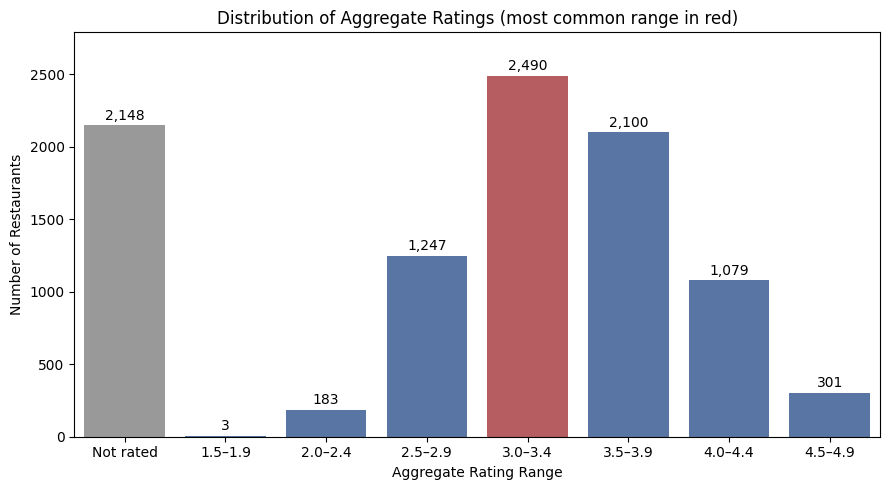

In [21]:
chart_df = pd.concat([pd.Series({"Not rated": unrated}), range_counts]).reset_index()
chart_df.columns = ["Rating Range", "Restaurant Count"]

colors = [
    "#999999" if r == "Not rated" else ("#C44E52" if r == top_range else "#4C72B0")
    for r in chart_df["Rating Range"]
]

plt.figure(figsize=(9, 5))
ax = sns.barplot(data=chart_df, x="Rating Range", y="Restaurant Count",
                 palette=colors, hue="Rating Range", legend=False)
for i, v in enumerate(chart_df["Restaurant Count"]):
    ax.text(i, v + 40, f"{v:,}", ha="center")
plt.ylim(0, chart_df["Restaurant Count"].max() + 300)
plt.title("Distribution of Aggregate Ratings (most common range in red)")
plt.xlabel("Aggregate Rating Range")
plt.ylabel("Number of Restaurants")
plt.tight_layout()
plt.show()

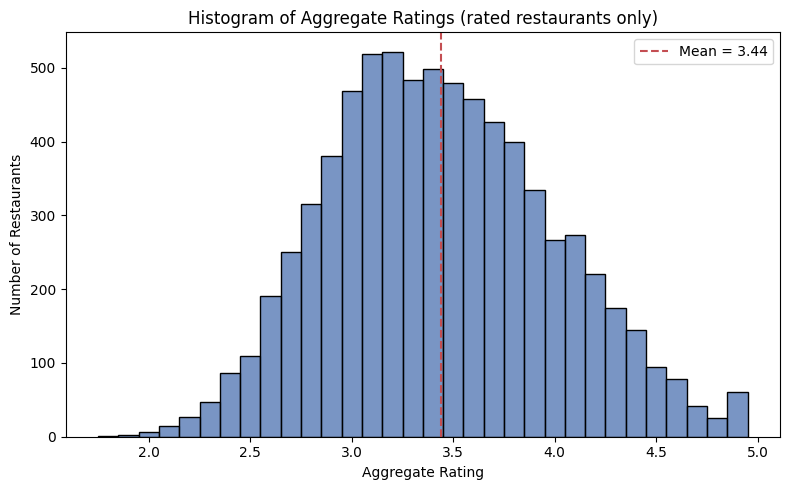

In [22]:
plt.figure(figsize=(8, 5))
sns.histplot(rated_df["Aggregate rating"], bins=np.arange(1.75, 5.0, 0.1), color="#4C72B0")
plt.axvline(rated_df["Aggregate rating"].mean(), color="#C44E52", linestyle="--",
            label=f"Mean = {rated_df['Aggregate rating'].mean():.2f}")
plt.title("Histogram of Aggregate Ratings (rated restaurants only)")
plt.xlabel("Aggregate Rating")
plt.ylabel("Number of Restaurants")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Average Number of Votes

In [23]:
votes = df["Votes"]

votes_summary = pd.DataFrame({
    "Metric": ["Average (mean) votes", "Median votes", "Maximum votes", "Minimum votes", "Restaurants with 0 votes"],
    "Value": [f"{votes.mean():.2f}", f"{votes.median():.0f}", f"{votes.max():,}", f"{votes.min()}", f"{(votes == 0).sum():,}"]
})
votes_summary

,Metric,Value
0,Average (mean) votes,156.91
1,Median votes,31
2,Maximum votes,"10,934"
3,Minimum votes,0
4,Restaurants with 0 votes,"1,094"


In [24]:
avg_votes = votes.mean()
print(f"Average votes per restaurant: {avg_votes:.2f}")
print(f"Share of restaurants below the average: {(votes < avg_votes).mean() * 100:.2f}%")

Average votes per restaurant: 156.91
Share of restaurants below the average: 78.21%


The mean is much larger than the median, so a small number of very popular
restaurants pull the average up. The median (31) describes a typical
restaurant better than the mean (156.91).

In [25]:
unrated_df = df[df["Aggregate rating"] == 0]

votes_by_group = pd.DataFrame({
    "Group": ["Rated restaurants", "Unrated restaurants"],
    "Restaurants": [len(rated_df), len(unrated_df)],
    "Average Votes": [round(rated_df["Votes"].mean(), 2), round(unrated_df["Votes"].mean(), 2)],
    "Median Votes": [rated_df["Votes"].median(), unrated_df["Votes"].median()],
})
votes_by_group

,Group,Restaurants,Average Votes,Median Votes
0,Rated restaurants,7403,202.19,60.0
1,Unrated restaurants,2148,0.87,0.0


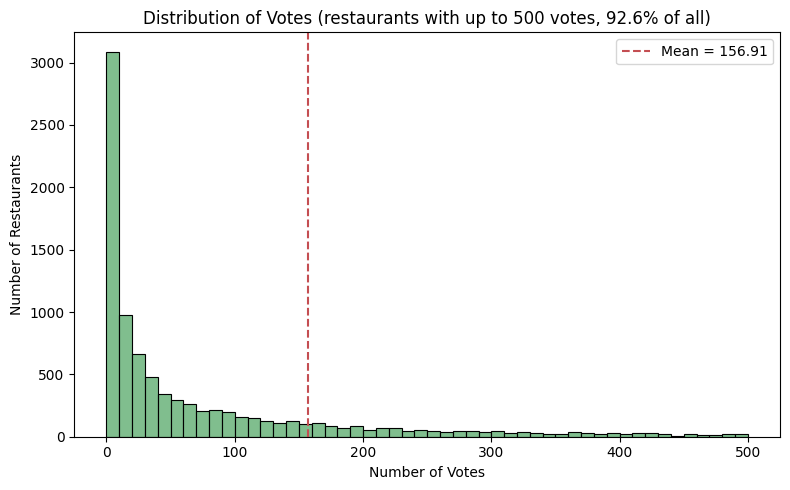

In [26]:
cap = 500
share_shown = (votes <= cap).mean() * 100

plt.figure(figsize=(8, 5))
sns.histplot(votes[votes <= cap], bins=50, color="#55A868")
plt.axvline(avg_votes, color="#C44E52", linestyle="--", label=f"Mean = {avg_votes:.2f}")
plt.title(f"Distribution of Votes (restaurants with up to {cap} votes, {share_shown:.1f}% of all)")
plt.xlabel("Number of Votes")
plt.ylabel("Number of Restaurants")
plt.legend()
plt.tight_layout()
plt.show()

## 5. Final Results

In [27]:
task_result = pd.DataFrame({
    "Question": [
        "Most common rating range",
        "Restaurants in that range",
        "Share of rated restaurants in that range",
        "Average votes per restaurant",
        "Median votes per restaurant",
    ],
    "Answer": [
        top_range,
        f"{top_range_count:,}",
        f"{top_range_count / len(rated_df) * 100:.2f}%",
        f"{avg_votes:.2f}",
        f"{votes.median():.0f}",
    ],
})
task_result

,Question,Answer
0,Most common rating range,3.0–3.4
1,Restaurants in that range,"2,490"
2,Share of rated restaurants in that range,33.64%
3,Average votes per restaurant,156.91
4,Median votes per restaurant,31


## 6. Validation

In [28]:
print("Total restaurants:", len(df))
print("Rated + unrated = total:", len(rated_df) + unrated == len(df))
print("Rating range counts add up to rated total:", range_counts.sum() == len(rated_df))
print("Overall average rating (all):", round(df["Aggregate rating"].mean(), 2))
print("Overall average rating (rated only):", round(rated_df["Aggregate rating"].mean(), 2))

Total restaurants: 9551
Rated + unrated = total: True
Rating range counts add up to rated total: True
Overall average rating (all): 2.67
Overall average rating (rated only): 3.44


### Business Insights

- **Most restaurants are rated in the middle.** The most common rating range is
  **3.0–3.4** with **2,490 restaurants (33.64% of rated restaurants)**, followed
  by 3.5–3.9 (2,100) and 2.5–2.9 (1,247). These three ranges cover about 79%
  of rated restaurants.
- **Very low and very high ratings are rare.** Only 186 restaurants (about
  2.5% of rated ones) score below 2.5, and just 301 (about 4%) score 4.5 or
  above. Ratings in this dataset only go up to 4.9, so no restaurant has a
  perfect score.
- **22.49% of listings (2,148) are unrated.** They have a rating of 0, which
  means "Not rated" and not "bad". Including them pulls the overall average to
  2.67, while the average of rated restaurants is 3.44.
- **The average restaurant has 156.91 votes**, but this is misleading. The
  median is only **31**, and 78.21% of restaurants have fewer votes than the
  average. A few very popular restaurants (up to 10,934 votes) pull the mean up,
  so the median describes a typical restaurant better.
-  **Unrated restaurants are essentially restaurants nobody has voted on.**
  Rated restaurants average 202.19 votes (median 60), while unrated ones
  average just 0.87 votes. In total, 1,094 restaurants (11.45%) have no votes
  at all.
- **Caution:** an average rating built from very few votes is less reliable.
  A restaurant with 3 votes and a 4.5 rating is not directly comparable to one
  with 1,000 votes and a 4.2 rating.